# Serie I · Campo — 01. Auditoría y análisis exploratorio

**Pregunta de negocio:** ¿qué variedades ampliar y cada cuántos cortes renovar?
Antes de modelar hay que saber qué tan confiables son los datos y qué sesgos traen.

**Dataset:** ensayos del programa de mejoramiento de caña de Louisiana, 2010-2021
(`data/raw/All_Genotypes_2010_onwards.csv`, sin modificar).

**Cómo correr:** desde la carpeta `notebooks/`, ejecutar todas las celdas en orden.
Toda cifra de este notebook sale del código; nada se escribe a mano.

**Contenido**
1. Auditoría del formato del archivo
2. Unidades: qué significa realmente cada columna
3. Limpieza (reglas y su impacto)
4. Estructura del diseño experimental
5. Hallazgos que condicionan el modelado
6. Resumen y decisiones para el siguiente notebook

In [1]:
import sys, csv, re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import statsmodels.api as sm

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from campo_data import load_raw, clean, identity_checks, check_varieties, MEASURES

RAW = ROOT / "data" / "raw" / "All_Genotypes_2010_onwards.csv"
FIG = ROOT / "outputs" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
TAB = ROOT / "outputs" / "tables"; TAB.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

# Estilo de gráficas: marcas delgadas, ejes recesivos, colores categóricos en orden fijo
AZUL, NARANJA, AQUA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#9a9993"
TINTA, TINTA2, REJILLA = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": REJILLA, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": TINTA, "font.size": 10,
})
def guardar(fig, nombre):
    fig.tight_layout(); fig.savefig(FIG / nombre, bbox_inches="tight"); plt.show()

## 1. Auditoría del formato del archivo

Primero se lee el CSV **como texto**, sin dejar que pandas adivine tipos, para ver qué trae realmente.

In [2]:
with open(RAW, encoding="utf-8-sig", newline="") as f:
    filas = list(csv.reader(f))
print("Encabezado:", filas[0])
print("Filas de datos:", len(filas) - 1)
notas = [r[14] for r in filas[1:] if r[14].strip()]
print("Contenido de la última columna (no son datos):", notas)

Encabezado: ['CLONE', 'YEAR', 'STAGE', 'LOC', 'CROP', 'REP', 'T_SPACRE', 'TRS_TON', 'TCA', 'POPN', 'MSTWT', 'FIBER', '', '', '']
Filas de datos: 29529
Contenido de la última columna (no son datos): ['T_SPACRE, ons of sugar per acre', 'Rep, replication', 'TRS, theoretical recoverable sugar', 'TCA, ton of cane per acre', 'POPN, population', 'MSTWT, mean stalk weight']


**Lo que trae el archivo:**
- Un BOM al inicio del encabezado y **3 columnas extra sin nombre**. Dos están vacías; la tercera tiene
  un mini-diccionario de 6 notas pegado en las primeras filas. No son datos y se descartan.
- Ese diccionario dice *"T_SPACRE, ons [tons] of sugar per acre"*, igual que el PDF de la prueba.
  En la sección 2 se demuestra que **es falso**: son libras.
- Los faltantes vienen como `"."` (y vacío en MSTWT y FIBER).

In [3]:
raw = load_raw(RAW)
patron = raw["TRS_TON"].str.match(r"^\d+\s+")
print(f"Filas con TRS_TON no numérico del tipo '63    202.317': {patron.sum():,} ({patron.mean():.1%})")
display(raw.loc[patron, ["CLONE","YEAR","LOC","CROP","T_SPACRE","TRS_TON","TCA"]].head(5))
display(pd.crosstab(raw["YEAR"], patron, normalize="index").rename(columns={False:"ok", True:"partida"}).round(3))

Filas con TRS_TON no numérico del tipo '63    202.317': 10,485 (35.5%)


,CLONE,YEAR,LOC,CROP,T_SPACRE,TRS_TON,TCA
4564,L99-233,2010,AFH,0,9977,79 227.620,43.8
4575,HOCP04-838,2017,AFL,0,10841,58 262.506,41.3
4578,L99-233,2013,AFL,2,11199,44 272.000,41.2
4580,L99-233,2012,STO,2,3247,51 166.660,19.5
4581,L99-233,2013,BLK,2,11747,69 241.000,48.7


TRS_TON,ok,partida
YEAR,,
2010,0.418,0.582
2011,0.428,0.572
2012,0.481,0.519
2013,0.528,0.472
2014,0.573,0.427
2015,0.616,0.384
2016,0.619,0.381
2017,0.674,0.326
2018,0.686,0.314


**Hallazgo 1 · El 35.5 % de las filas venía partido por una coma decimal.**
En 2010-2019, T_SPACRE se exportó con coma decimal (`"1355,63"`). El CSV usa coma como separador,
así que el valor se partió en dos: T_SPACRE quedó con la parte entera (`1355`) y TRS_TON quedó
como `"63    202.317"` (decimales + espacios + el TRS real).
Si se lee el archivo con `pd.read_csv` sin revisar, esas filas pierden TRS (queda como texto) y
T_SPACRE pierde decimales. **Ninguna fila de 2020-2021 tiene el problema**: el archivo es la unión
de dos exportaciones distintas (más evidencia en la sección 2).

**Reparación:** T_SPACRE = parte entera + "." + decimales; TRS_TON = número después de los espacios.
Se valida con la identidad de la sección 2.

## 2. Unidades: qué significa realmente cada columna

Si las unidades son las que documenta el autor del dataset (USDA-ARS), deben cumplirse dos identidades:

- **Azúcar:** `T_SPACRE (lb/acre) = TCA (t/acre) × TRS_TON (lb/t)`
- **Caña:** `TCA (t/acre) = POPN (tallos/acre) × MSTWT (lb/tallo) / 2000`

In [4]:
df, log = clean(raw)
ic = identity_checks(df)
ic["YEAR"] = df["YEAR"]
resumen = ic.groupby("YEAR").agg(
    azucar_mediana=("azucar", "median"), azucar_p01=("azucar", lambda s: s.quantile(.01)),
    azucar_p99=("azucar", lambda s: s.quantile(.99)), cana_mediana=("cana", "median"))
display(resumen.round(4))
print(f"Filas donde T_SPACRE se aleja > 2 % de TCA × TRS: {(ic['azucar'].sub(1).abs() > .02).sum()} de {len(ic):,}")

# POPN en 2020-2021, leído del archivo crudo (la limpieza lo anula)
popn =pd.DataFrame({"YEAR": raw["YEAR"].astype(int), "POPN": pd.to_numeric(raw["POPN"].replace(".", np.nan), errors="coerce")})
print("Mediana de POPN por año:", popn.groupby("YEAR")["POPN"].median().round(1).to_dict())

,azucar_mediana,azucar_p01,azucar_p99,cana_mediana
YEAR,,,,
2010,1.0000,0.9972,1.0025,1.0001
2011,1.0000,0.9974,1.0022,1.0000
2012,1.0000,0.9977,1.0020,1.0000
2013,1.0000,0.9980,1.0020,0.9999
2014,1.0000,0.9979,1.0021,1.0000
2015,1.0000,0.9977,1.0025,0.9999
2016,1.0000,0.9971,1.0032,0.9999
2017,1.0000,0.9976,1.0020,0.9999
2018,1.0000,0.9982,1.0017,0.9999


Filas donde T_SPACRE se aleja > 2 % de TCA × TRS: 8 de 29,205
Mediana de POPN por año: {2010: 30855.0, 2011: 34107.6, 2012: 36409.5, 2013: 35846.3, 2014: 33577.5, 2015: 34938.8, 2016: 32675.9, 2017: 33820.9, 2018: 34030.0, 2019: 32559.6, 2020: 11.9, 2021: 12.1}


**Hallazgo 2 · T_SPACRE son libras de azúcar por acre, no toneladas.**
La identidad se cumple con error menor a 0.3 % en prácticamente todas las filas (incluidas las
10,485 reparadas, lo que valida la reparación). Una mediana de ~9,100 lb/acre equivale a ~4.6 t
de azúcar por acre. Esto importa para la economía: el precio está en US$/lb, así que
**ingreso = T_SPACRE × 0.20**. Si se tomara como toneladas, el ingreso saldría inflado ×2,000.

**Hallazgo 3 · POPN cambia de unidad en 2020.** En 2010-2019, POPN son tallos por acre
(~33,000) y la identidad de caña se cumple exacta. En 2020-2021 la mediana es ~12 y la identidad
no cuadra con ninguna conversión simple. Más señales de que 2020-2021 viene de otra exportación:
la fibra se midió en el 98 % de las filas (vs ~32 % antes) y el TRS trae 2 decimales en vez de 3.
**Decisión:** POPN de 2020-2021 → faltante. No afecta el modelo porque POPN no se usará como
predictor (se mide en la cosecha; ver sección 5).

## 3. Limpieza: reglas y su impacto

Todas las reglas viven en `src/campo_data.py` (la misma función la usará la API).

In [5]:
desc = {
    "reparadas_coma_decimal": "T_SPACRE/TRS partidos por coma decimal → reconstruidos",
    "cero_a_nan_T_SPACRE": "Ceros en T_SPACRE (vienen con TCA vacío) → faltante",
    "cero_a_nan_TRS_TON": "Ceros en TRS → faltante", "cero_a_nan_TCA": "Ceros en TCA → faltante",
    "cero_a_nan_POPN": "Ceros en POPN → faltante", "cero_a_nan_MSTWT": "Ceros en MSTWT → faltante",
    "popn_2020_2021_a_nan": "POPN 2020-2021 en unidad desconocida → faltante",
    "tca_o_mstwt_imposible_fila_a_nan": "TCA > 100 t/acre o MSTWT > 6 lb (p. ej. 518 t/acre, error ×10) → faltante",
    "trs_imposible_a_nan": "TRS fuera de 120-400 lb/t (p. ej. 478) → faltante",
    "fibra_imposible_a_nan": "Fibra fuera de 6-22 % (p. ej. 4.1 %) → faltante",
    "loc_renombrada": "'DOMINGUES' (plantía 2019) = 'DOMINGUE' (socas 2020-21): mismo ensayo",
    "duplicados_exactos_eliminados": "Filas idénticas en llave y mediciones (doble captura)",
    "sin_T_SPACRE_eliminadas": "Filas sin variable objetivo",
}
tabla_log = pd.DataFrame([(desc.get(k, k), v) for k, v in log.items()], columns=["Regla", "Filas"])
tabla_log.to_csv(TAB / "serie1_limpieza.csv", index=False)
display(tabla_log)

,Regla,Filas
0,filas_originales,29529
1,T_SPACRE/TRS partidos por coma decimal → recon...,10485
2,Ceros en T_SPACRE (vienen con TCA vacío) → fal...,14
3,Ceros en TRS → faltante,1
4,Ceros en TCA → faltante,2
5,Ceros en POPN → faltante,1
6,Ceros en MSTWT → faltante,1
7,POPN 2020-2021 en unidad desconocida → faltante,1125
8,TCA > 100 t/acre o MSTWT > 6 lb (p. ej. 518 t/...,5
9,TRS fuera de 120-400 lb/t (p. ej. 478) → faltante,4


In [6]:
llave = ["CLONE", "YEAR", "STAGE", "LOC", "CROP", "REP"]
rep_llave = df[df.duplicated(llave, keep=False)]
print(f"Filas que comparten llave pero con mediciones distintas: {len(rep_llave)}")
print("Clones involucrados:", sorted(rep_llave['CLONE'].unique()))

Filas que comparten llave pero con mediciones distintas: 212
Clones involucrados: ['HO12-615', 'HOCP09-804', 'HOCP96-540', 'L01-283', 'L01-299', 'L12-201', 'L99-226', 'L99-233', 'LCP85-384']


**Hallazgo 4 · Llaves repetidas que no son duplicados.** Después de quitar las dobles capturas,
quedan filas con la misma llave (clon, año, etapa, localidad, corte, repetición) pero mediciones
distintas. Son todas variedades comerciales (testigos y dos variedades antiguas): la misma variedad
sembrada en dos ensayos paralelos en la misma localidad y año. El archivo no trae un identificador de ensayo que las separe.
**Decisión:** se conservan y se promedian al nivel parcela (clon × ensayo × corte).

## 4. Estructura del diseño experimental

Se define un **ensayo** como etapa × localidad × año de siembra (`PLANT_YEAR = YEAR − CROP`):
una plantía y sus socas en años siguientes pertenecen al mismo ensayo.

In [7]:
plot = (df.groupby(["TRIAL","STAGE","LOC","PLANT_YEAR","ENV","CLONE","CROP","YEAR"], as_index=False)
          [["T_SPACRE","TCA","TRS_TON","FIBER"]].mean())   # promedio de repeticiones = parcela

estructura = df.groupby("STAGE").agg(
    clones=("CLONE","nunique"), localidades=("LOC","nunique"), ensayos=("TRIAL","nunique"),
    filas=("CLONE","size"), reps_max=("REP","max"), corte_max=("CROP","max"))
display(estructura)
display(pd.crosstab(df["STAGE"], df["CROP"], margins=True))

,clones,localidades,ensayos,filas,reps_max,corte_max
STAGE,,,,,,
2,904,2,16,2177,1,2
3,743,10,120,11093,2,3
4,137,8,44,1906,2,3
5,40,14,160,14029,3,4


CROP,0,1,2,3,4,All
STAGE,,,,,,
2,815,902,460,0,0,2177
3,6272,2772,1613,436,0,11093
4,961,484,296,165,0,1906
5,4527,3869,3609,1940,84,14029
All,12575,8027,5978,2541,84,29205


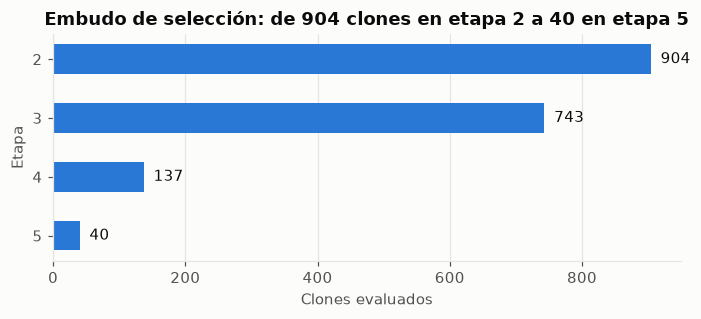

In [8]:
fig, ax = plt.subplots(figsize=(6.5, 3))
x = estructura.index.astype(str)
ax.barh(x[::-1], estructura["clones"][::-1], color=AZUL, height=0.5)
for i, v in enumerate(estructura["clones"][::-1]):
    ax.text(v + 15, i, f"{v}", va="center", color=TINTA)
ax.set_xlabel("Clones evaluados"); ax.set_ylabel("Etapa")
ax.set_title("Embudo de selección: de 904 clones en etapa 2 a 40 en etapa 5")
ax.grid(axis="y", visible=False)
guardar(fig, "serie1_01_embudo.png")

**Testigos.** Un candidato pasa por las etapas 2-3 en 1-3 cohortes y luego avanza o se descarta.
Solo las variedades comerciales de referencia se siembran ahí año tras año. Regla: **testigo = clon
sembrado en etapas 2-3 en al menos 4 cohortes distintas**. El corte es limpio (157 clones con 3
cohortes, ninguno típico con 4+ salvo los testigos).

In [9]:
cohortes = df[df["STAGE"] <= 3].groupby("CLONE")["PLANT_YEAR"].nunique()
print("Distribución de cohortes en etapas 2-3:", cohortes.value_counts().sort_index().to_dict())
TESTIGOS = check_varieties(df)
print(f"{len(TESTIGOS)} testigos:", TESTIGOS)
df["TESTIGO"] = df["CLONE"].isin(TESTIGOS); plot["TESTIGO"] = plot["CLONE"].isin(TESTIGOS)
print("¿Todos los ensayos tienen al menos un testigo?", df.groupby("TRIAL")["TESTIGO"].any().all())
print("Clones en etapa 5 que no son testigos:", sorted(set(df[df.STAGE==5].CLONE) - set(TESTIGOS)))

Distribución de cohortes en etapas 2-3: {1: 599, 2: 388, 3: 157, 4: 2, 5: 3, 6: 1, 8: 2, 9: 2, 12: 1, 15: 1}
12 testigos: ['HO12-615', 'HO13-739', 'HOCP00-950', 'HOCP04-838', 'HOCP09-804', 'HOCP96-540', 'L01-283', 'L01-299', 'L03-371', 'L11-183', 'L12-201', 'L99-226']
¿Todos los ensayos tienen al menos un testigo? True
Clones en etapa 5 que no son testigos: ['CP01-1372', 'HO05-961', 'HO07-613', 'HO09-840', 'HO11-515', 'HO11-532', 'HO11-573', 'HO12-630', 'HO13-708', 'HO15-971', 'HO16-600', 'HO16-608', 'HO17-738', 'HO95-988', 'HOCP13-740', 'HOCP13-758', 'HOCP14-802', 'HOCP14-885', 'HOCP17-701', 'HOL15-508', 'L08-090', 'L09-112', 'L13-251', 'L14-267', 'L15-306', 'L97-128', 'L99-233', 'LCP85-384']


Todos los ensayos tienen testigos. Eso permite la comparación más simple y defendible:
**cada clon contra los testigos del mismo ensayo y el mismo corte** (mismo lugar, año y suelo).

## 5. Hallazgos que condicionan el modelado

### 5.1 Las etapas tempranas inflan el rendimiento por acre
Se comparan **las mismas variedades testigo**, en plantía, según la etapa donde se sembraron.

,TCA,TRS_TON,T_SPACRE
STAGE,,,
2,49.3,249.6,12416.0
3,41.2,260.6,10727.9
4,38.7,260.4,10058.5
5,32.3,280.5,9058.3


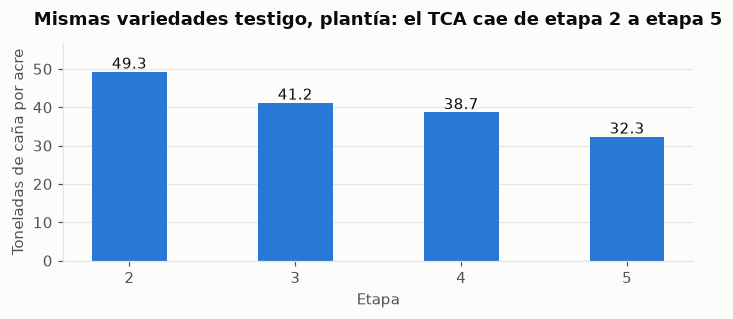

Pares clon-año en etapa 2 y 5: 33 | TCA etapa 2 / etapa 5: media 1.54, mediana 1.58


In [10]:
g = plot[plot["TESTIGO"] & (plot["CROP"] == 0)].groupby("STAGE")[["TCA","TRS_TON","T_SPACRE"]].mean()
display(g.round(1))
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.bar(g.index.astype(str), g["TCA"], color=AZUL, width=0.45)
for i, v in enumerate(g["TCA"]):
    ax.text(i, v + 0.8, f"{v:.1f}", ha="center", color=TINTA)
ax.set_xlabel("Etapa"); ax.set_ylabel("Toneladas de caña por acre")
ax.set_title("Mismas variedades testigo, plantía: el TCA cae de etapa 2 a etapa 5", pad=12)
ax.set_ylim(0, g["TCA"].max() * 1.15); ax.grid(axis="x", visible=False)
guardar(fig, "serie1_02_inflacion_etapa.png")

# Control: mismo clon y mismo año sembrado en etapa 2 y en etapa 5 (descarta diferencias de años o de clones)
par = plot[plot["TESTIGO"] & (plot["CROP"] == 0)].groupby(["CLONE","YEAR","STAGE"])["TCA"].mean().unstack().dropna(subset=[2, 5])
print(f"Pares clon-año en etapa 2 y 5: {len(par)} | TCA etapa 2 / etapa 5: media {(par[2]/par[5]).mean():.2f}, mediana {(par[2]/par[5]).median():.2f}")

**Hallazgo 5.** Las mismas variedades rinden ~49 t/acre en etapa 2 y ~32 t/acre en etapa 5. Comparando
el mismo clon en el mismo año, la etapa 2 rinde ~1.5 veces más. No son mejores en etapa 2: las parcelas tempranas son pequeñas y en estación experimental (efecto de
borde, mejor manejo). **Decisión:** los valores absolutos de etapas 2-4 no sirven para la economía.
La recomendación económica se calcula con **etapa 5** (localidades con nombre de finca: ensayos en
campo comercial), y las etapas 2-4 solo se usan en términos relativos a testigos.

### 5.2 El ambiente (localidad × año) pesa más que la variedad

,df,pct
Localidad × año,141.0,40.1
Variedad,39.0,9.4
Número de corte,4.0,13.4
Residual (interacción + error),4523.0,37.1


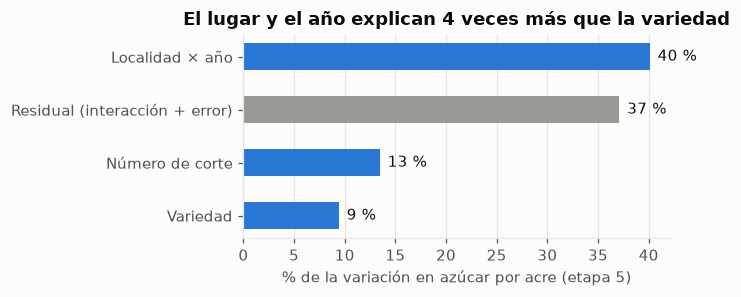

In [11]:
s5 = plot[plot["STAGE"] == 5].copy()
anova = sm.stats.anova_lm(smf.ols("T_SPACRE ~ C(ENV) + C(CLONE) + C(CROP)", data=s5).fit(), typ=1)
anova["pct"] = 100 * anova["sum_sq"] / anova["sum_sq"].sum()
nombres = {"C(ENV)": "Localidad × año", "C(CLONE)": "Variedad", "C(CROP)": "Número de corte", "Residual": "Residual (interacción + error)"}
anova.index = anova.index.map(nombres)
display(anova[["df","pct"]].round(1))

fig, ax = plt.subplots(figsize=(6.5, 2.8))
orden = anova["pct"].sort_values()
ax.barh(orden.index, orden.values, color=[GRIS if "Residual" in i else AZUL for i in orden.index], height=0.5)
for i, v in enumerate(orden.values):
    ax.text(v + 0.8, i, f"{v:.0f} %", va="center", color=TINTA)
ax.set_xlabel("% de la variación en azúcar por acre (etapa 5)")
ax.set_title("El lugar y el año explican 4 veces más que la variedad")
ax.grid(axis="y", visible=False)
guardar(fig, "serie1_03_varianza.png")

**Hallazgo 6.** En etapa 5, localidad × año explica ~40 % de la variación del azúcar por acre; la
variedad, ~9 %. Comparar promedios crudos entre clones es comparar dónde y cuándo se sembraron.
**Decisión:** toda comparación entre clones se hace dentro del mismo ambiente (contra testigos).

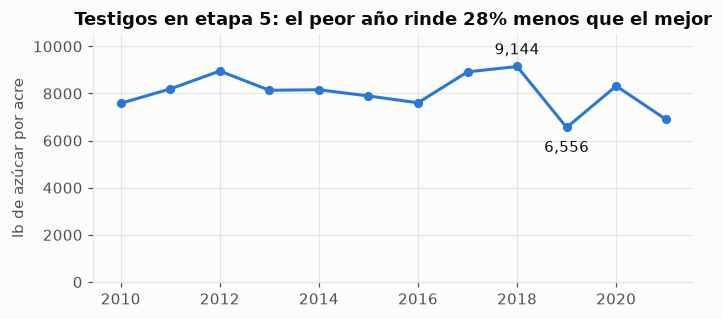

Rango año peor/mejor: 0.717


In [12]:
anual = s5[s5["TESTIGO"]].groupby("YEAR")["T_SPACRE"].mean()
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.plot(anual.index, anual.values, color=AZUL, marker="o", markersize=5)
for yr, dy in [(anual.idxmax(), 8), (anual.idxmin(), -16)]:
    ax.annotate(f"{anual[yr]:,.0f}", (yr, anual[yr]), textcoords="offset points", xytext=(0, dy), ha="center", color=TINTA)
ax.set_ylabel("lb de azúcar por acre")
ax.set_title(f"Testigos en etapa 5: el peor año rinde {1 - anual.min()/anual.max():.0%} menos que el mejor")
ax.set_ylim(0, anual.max() * 1.15)
guardar(fig, "serie1_04_efecto_anio.png")
print("Rango año peor/mejor:", round(anual.min() / anual.max(), 3))

### 5.3 Sesgo de supervivencia: solo los buenos llegan a socas y a etapas avanzadas

In [13]:
pc = plot[plot["CROP"] == 0].copy()
pc["rel"] = pc["T_SPACRE"] / pc.groupby("TRIAL")["T_SPACRE"].transform("mean")

# (a) dentro del ensayo: ¿los clones que siguen a primera soca tenían mejor plantía?
con_soca = set(plot.loc[plot["CROP"] == 1, "TRIAL"])
sig = plot.loc[plot["CROP"] == 1, ["TRIAL","CLONE"]].assign(sigue=True)
a = pc[pc["TRIAL"].isin(con_soca) & ~pc["TESTIGO"]].merge(sig, on=["TRIAL","CLONE"], how="left").fillna({"sigue": False})
tabla_a = a.groupby(["STAGE","sigue"])["rel"].agg(["mean","size"]).round(3)
display(tabla_a)

# (b) entre etapas: ¿los que avanzan tenían mejor plantía? (cohortes ≤ 2017 para dar tiempo a avanzar)
def avance(desde, hacia):
    x = pc[(pc["STAGE"] == desde) & ~pc["TESTIGO"] & (pc["PLANT_YEAR"] <= 2017)].copy()
    x["avanza"] = x["CLONE"].isin(set(plot.loc[plot["STAGE"] >= hacia, "CLONE"]))
    return x.groupby("avanza")["rel"].mean()
b = pd.DataFrame({"2 → 3": avance(2, 3), "3 → 4": avance(3, 4)})
display(b.round(3))

mean  size
STAGE sigue             
2     False  0.816     2
      True   0.998   755
3     False  0.954  1424
      True   1.080   815
4     False  0.969   170
      True   1.084    89
5     False  1.003   153
      True   1.028   301

,2 → 3,3 → 4
avanza,,
False,0.968,0.967
True,1.024,1.079


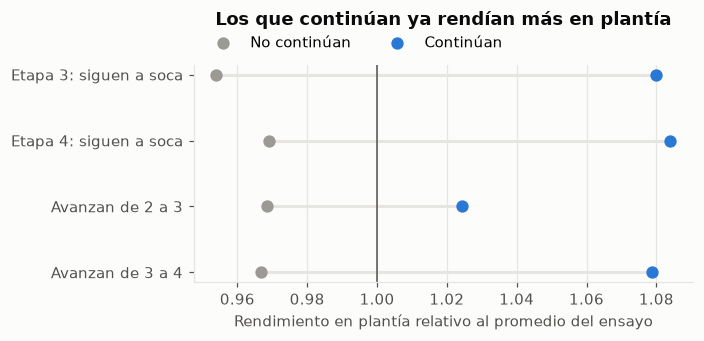

In [14]:
etq = ["Etapa 3: siguen a soca", "Etapa 4: siguen a soca", "Avanzan de 2 a 3", "Avanzan de 3 a 4"]
si = [tabla_a.loc[(3, True), "mean"], tabla_a.loc[(4, True), "mean"], b.loc[True, "2 → 3"], b.loc[True, "3 → 4"]]
no = [tabla_a.loc[(3, False), "mean"], tabla_a.loc[(4, False), "mean"], b.loc[False, "2 → 3"], b.loc[False, "3 → 4"]]
fig, ax = plt.subplots(figsize=(6.5, 3.2))
y = np.arange(len(etq))[::-1]
ax.hlines(y, no, si, color=REJILLA, linewidth=2)
ax.scatter(no, y, color=GRIS, s=50, zorder=3, label="No continúan")
ax.scatter(si, y, color=AZUL, s=50, zorder=3, label="Continúan")
ax.axvline(1, color=TINTA2, linewidth=1)
ax.set_yticks(y); ax.set_yticklabels(etq)
ax.set_xlabel("Rendimiento en plantía relativo al promedio del ensayo")
ax.set_title("Los que continúan ya rendían más en plantía", pad=26)
ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2); ax.grid(axis="y", visible=False)
guardar(fig, "serie1_05_supervivencia.png")

**Hallazgo 7.** En etapas 3 y 4, los clones que se siguieron evaluando en socas rendían 12-13 % más en
plantía que los que se dejaron de medir (1.08 vs 0.95-0.97 del promedio del ensayo). Lo mismo al avanzar de etapa. Consecuencias:
- Un promedio crudo de socas está hecho solo con los mejores → **subestima la caída de socas**.
- Los datos faltan **no al azar**: un clon sin socas no es "sin información", es "probablemente descartado".
**Decisión:** la caída de socas se estima dentro del mismo clon y ensayo, nunca comparando
promedios de grupos distintos de clones; y en etapa 5 (donde no hay descarte dentro del ensayo).

### 5.4 ¿Cuánto cae el rendimiento en cada soca? Tres formas de medirlo

In [15]:
# (1) Cruda: promedio por corte (grupos distintos de clones en cada corte)
cruda = s5.groupby("CROP")["T_SPACRE"].mean(); cruda = cruda / cruda.loc[0]

# (2) Dentro del ensayo: cada clon contra su propia plantía (mezcla el efecto del año)
base = s5[s5["CROP"] == 0][["TRIAL","CLONE","T_SPACRE"]].rename(columns={"T_SPACRE": "pc"})
w = s5.merge(base, on=["TRIAL","CLONE"])
dentro = (w["T_SPACRE"] / w["pc"]).groupby(w["CROP"]).median()

# (3) Ajustada: regresión log con efectos fijos de ambiente y clon.
#     Compara cortes distintos dentro del mismo lugar-año (136 de 142 ambientes tienen ≥2 cortes a la vez)
m_aj = smf.ols("np.log(T_SPACRE) ~ C(ENV) + C(CLONE) + C(CROP)", data=s5).fit()
ef = m_aj.params.filter(like="C(CROP)"); ci = m_aj.conf_int().loc[ef.index]
ajustada = pd.Series([1.0] + list(np.exp(ef)), index=range(5))
caida = pd.DataFrame({"cruda": cruda, "dentro_ensayo": dentro, "ajustada": ajustada,
                      "ajustada_ic95_inf": [1.0] + list(np.exp(ci[0])), "ajustada_ic95_sup": [1.0] + list(np.exp(ci[1]))})
caida["parcelas"] = s5.groupby("CROP").size()
caida.index.name = "corte"
caida.to_csv(TAB / "serie1_caida_socas.csv")
display(caida.round(3))

,cruda,dentro_ensayo,ajustada,ajustada_ic95_inf,ajustada_ic95_sup,parcelas
corte,,,,,,
0,1.000,1.000,1.000,1.000,1.000,1518
1,0.912,0.917,0.928,0.915,0.942,1297
2,0.785,0.783,0.800,0.788,0.812,1214
3,0.723,0.695,0.720,0.706,0.734,651
4,0.730,0.608,0.650,0.599,0.704,28


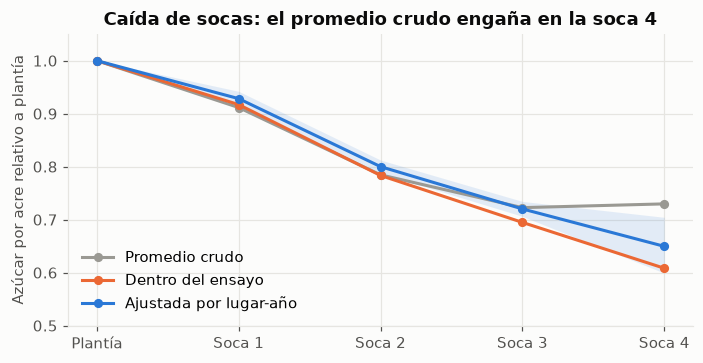

In [16]:
fig, ax = plt.subplots(figsize=(6.5, 3.4))
etiquetas = {"cruda": ("Promedio crudo", GRIS), "dentro_ensayo": ("Dentro del ensayo", NARANJA), "ajustada": ("Ajustada por lugar-año", AZUL)}
for col, (nom, colr) in etiquetas.items():
    ax.plot(caida.index, caida[col], color=colr, marker="o", markersize=5, label=nom)
ax.fill_between(caida.index, caida["ajustada_ic95_inf"], caida["ajustada_ic95_sup"], color=AZUL, alpha=0.12, linewidth=0)
ax.set_xticks(range(5)); ax.set_xticklabels(["Plantía", "Soca 1", "Soca 2", "Soca 3", "Soca 4"])
ax.set_ylabel("Azúcar por acre relativo a plantía"); ax.set_ylim(0.5, 1.05)
ax.set_title("Caída de socas: el promedio crudo engaña en la soca 4")
ax.legend(frameon=False, loc="lower left")
guardar(fig, "serie1_06_caida_socas.png")

**Hallazgo 8.** Ajustando por lugar-año, una caña típica rinde 93 %, 80 %, 72 % y 65 % de su
plantía en socas 1 a 4 (intervalos de ±1-5 %). El promedio crudo dice que la soca 4 rinde igual que
la 3 (73 %): falso, porque a soca 4 solo llegaron 28 parcelas de ensayos buenos. Comparar contra la
propia plantía (naranja) mezcla el efecto del año y exagera la caída en soca 4 (61 %).
**Decisión:** para la economía de renovación se usan las caídas **ajustadas**. La soca 4 tiene muy
poca evidencia (28 parcelas): la recomendación no puede extrapolar más allá de 5 cortes.

### 5.5 La longevidad sí cambia entre variedades

In [17]:
# Se quita el efecto lugar-año y se mide, para cada clon, cuánto cae por corte (pendiente en escala log).
amb = m_aj.params.filter(like="C(ENV)")
amb.index = amb.index.str.replace(r"C\(ENV\)\[T\.(.*)\]", r"\1", regex=True)
s5["log_aj"] = np.log(s5["T_SPACRE"]) - s5["ENV"].map(amb).fillna(0.0)
elegibles = s5.groupby("CLONE")["CROP"].nunique().loc[lambda s: s >= 3].index

filas = []
for clon, g in s5[s5["CLONE"].isin(elegibles)].groupby("CLONE"):
    r = smf.ols("log_aj ~ CROP", data=g).fit()
    lo, hi = r.conf_int().loc["CROP"]
    filas.append({"CLONE": clon, "retencion_por_corte": np.exp(r.params["CROP"]),
                  "ic95_inf": np.exp(lo), "ic95_sup": np.exp(hi), "parcelas": len(g),
                  "cortes": g["CROP"].max() + 1, "testigo": clon in TESTIGOS})
longev = pd.DataFrame(filas).sort_values("retencion_por_corte")
longev.to_csv(TAB / "serie1_longevidad.csv", index=False)
display(longev.round(3))

# Prueba formal: ¿la pendiente difiere entre clones?
d = s5[s5["CLONE"].isin(elegibles)]
m0 = smf.ols("np.log(T_SPACRE) ~ C(ENV) + C(CLONE) + CROP", data=d).fit()
m1 = smf.ols("np.log(T_SPACRE) ~ C(ENV) + C(CLONE) + CROP + C(CLONE):CROP", data=d).fit()
print(sm.stats.anova_lm(m0, m1))

,CLONE,retencion_por_corte,ic95_inf,ic95_sup,parcelas,cortes,testigo
1,HO07-613,0.826,0.804,0.848,234,5,False
11,HOCP96-540,0.832,0.814,0.851,451,5,True
3,HO11-573,0.852,0.809,0.897,43,5,False
17,L11-183,0.866,0.845,0.888,209,5,True
0,HO05-961,0.886,0.864,0.909,163,4,False
21,L99-226,0.886,0.871,0.902,277,5,True
22,L99-233,0.887,0.867,0.908,160,4,False
5,HO12-630,0.888,0.835,0.944,59,3,False
8,HOCP04-838,0.888,0.874,0.903,424,5,True
10,HOCP14-885,0.891,0.858,0.926,100,4,False


   df_resid         ssr  df_diff   ss_diff          F        Pr(>F)
0    4315.0  157.157227      0.0       NaN        NaN           NaN
1    4293.0  148.709736     22.0  8.447492  11.084768  4.019933e-38


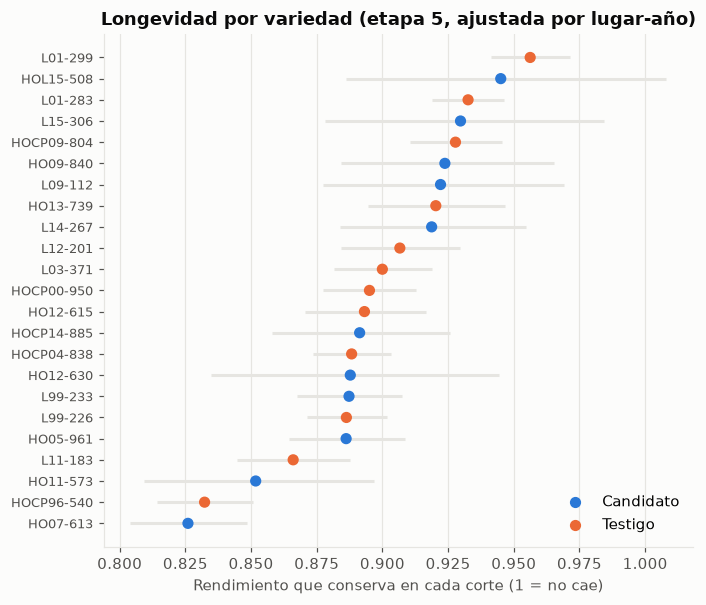

In [18]:
fig, ax = plt.subplots(figsize=(6.5, 5.6))
y = np.arange(len(longev))
cols = [NARANJA if t else AZUL for t in longev["testigo"]]
ax.hlines(y, longev["ic95_inf"], longev["ic95_sup"], color=REJILLA, linewidth=2)
ax.scatter(longev["retencion_por_corte"], y, color=cols, s=40, zorder=3)
ax.set_yticks(y); ax.set_yticklabels(longev["CLONE"], fontsize=8.5)
ax.set_xlabel("Rendimiento que conserva en cada corte (1 = no cae)")
ax.set_title("Longevidad por variedad (etapa 5, ajustada por lugar-año)")
ax.scatter([], [], color=AZUL, s=40, label="Candidato"); ax.scatter([], [], color=NARANJA, s=40, label="Testigo")
ax.legend(frameon=False, loc="lower right"); ax.grid(axis="y", visible=False)
guardar(fig, "serie1_07_longevidad.png")

**Hallazgo 9.** Hay variedades que conservan ~96 % de su rendimiento en cada corte (L01-299) y otras
que pierden ~17 % por corte (HO07-613, HOCP96-540). La
prueba F de la interacción clon × corte es contundente (p < 0.001), así que la longevidad es un
criterio real de selección, no ruido. **Decisión:** la recomendación combina dos cosas:
productividad relativa a testigos **y** longevidad propia de cada variedad (que define cada cuántos
cortes conviene renovarla).

### 5.6 Una parcela sola es muy ruidosa

In [19]:
for st in [3, 4, 5]:
    x = df[df["STAGE"] == st].pivot_table(index=["TRIAL","CROP","CLONE"], columns="REP", values="T_SPACRE", aggfunc="mean").dropna(subset=[1, 2])
    x = x.sub(x.groupby(level=["TRIAL","CROP"]).transform("mean"))   # quitar el efecto del ensayo
    print(f"Etapa {st}: correlación repetición 1 vs 2 = {x[1].corr(x[2]):.2f}  (n = {len(x):,})")

Etapa 3: correlación repetición 1 vs 2 = 0.40  (n = 5,442)
Etapa 4: correlación repetición 1 vs 2 = 0.41  (n = 934)
Etapa 5: correlación repetición 1 vs 2 = 0.44  (n = 4,654)


**Hallazgo 10.** Dos repeticiones del mismo clon en el mismo ensayo correlacionan apenas ~0.4. Una
sola parcela dice poco; la etapa 2 (sin repeticiones) es todavía más ruidosa. **Decisión:** solo se
recomiendan clones con evidencia en muchos ensayos, y se reporta la incertidumbre.

### 5.7 Tonelaje y calidad son independientes; el ranking por azúcar ≈ ranking por margen

In [20]:
ref = s5[s5["TESTIGO"]].groupby(["TRIAL","CROP"])[["T_SPACRE","TCA","TRS_TON"]].mean().add_suffix("_t")
z = s5.join(ref, on=["TRIAL","CROP"])
z["margen"] = z["T_SPACRE"] * 0.20 - 14 * z["TCA"] - 350
z["margen_t"] = z["T_SPACRE_t"] * 0.20 - 14 * z["TCA_t"] - 350
z["d_azucar"] = z["T_SPACRE"] - z["T_SPACRE_t"]; z["d_margen"] = z["margen"] - z["margen_t"]
z["r_tca"] = z["TCA"] / z["TCA_t"]; z["r_trs"] = z["TRS_TON"] / z["TRS_TON_t"]

clones5 = z.groupby("CLONE").agg(
    ensayos=("TRIAL","nunique"), parcelas=("d_azucar","size"), anios=("YEAR","nunique"),
    ultimo_corte=("CROP","max"), d_azucar_lb=("d_azucar","mean"), d_margen_usd=("d_margen","mean"),
    tca_vs_testigo=("r_tca","mean"), trs_vs_testigo=("r_trs","mean"))
clones5["testigo"] = clones5.index.isin(TESTIGOS)
clones5 = clones5.sort_values("d_azucar_lb", ascending=False)
clones5.to_csv(TAB / "serie1_clones_etapa5_vs_testigos.csv")
display(clones5.round(3))

rho = clones5[["d_azucar_lb","d_margen_usd"]].corr("spearman").iloc[0, 1]
print(f"Spearman ranking por azúcar vs ranking por margen: {rho:.3f}")
print(f"Correlación TCA relativo vs TRS relativo entre clones: {clones5[['tca_vs_testigo','trs_vs_testigo']].corr().iloc[0,1]:.2f}")
print(f"TRS de equilibrio del corte (14 / 0.20): {14/0.20:.0f} lb/t  |  TRS mínimo observado en etapa 5: {s5['TRS_TON'].min():.0f} lb/t")

,ensayos,parcelas,anios,ultimo_corte,d_azucar_lb,d_margen_usd,tca_vs_testigo,trs_vs_testigo,testigo
CLONE,,,,,,,,,
HO16-600,9,9,1,0,1567.992,298.235,1.028,1.137,False
HOCP14-885,42,100,4,3,1309.069,219.794,1.103,1.060,False
HO16-608,9,9,1,0,1149.322,163.432,1.134,0.987,False
HOCP13-758,21,31,2,1,863.548,147.996,1.052,1.035,False
L13-251,11,11,1,0,780.723,99.089,1.122,0.963,False
HOL15-508,31,61,3,2,739.457,141.291,1.026,1.077,False
HO12-615,64,178,6,4,671.782,89.251,1.105,0.980,True
L15-306,30,60,3,2,626.348,104.204,1.059,1.031,False
L01-299,137,393,12,4,568.076,78.125,1.092,0.986,True


Spearman ranking por azúcar vs ranking por margen: 0.982
Correlación TCA relativo vs TRS relativo entre clones: -0.07
TRS de equilibrio del corte (14 / 0.20): 70 lb/t  |  TRS mínimo observado en etapa 5: 142 lb/t


**Hallazgo 11 (corrige una hipótesis inicial).** Esperaba que el costo de US$14/t de corte cambiara
el ranking (variedades de mucho tonelaje y poca calidad). **Los datos no lo apoyan:** el ranking por
azúcar y el ranking por margen coinciden casi por completo (Spearman ≈ 0.98). La razón es aritmética:
una tonelada de caña con TRS típico (~280 lb/t) produce ~US$56 de azúcar contra US$14 de corte; el
corte solo deja de pagarse con TRS < 70 lb/t, y el mínimo observado está muy por encima. Además, tonelaje
y TRS relativos no están correlacionados (≈ 0), no hay un "trade-off" entre ellos.
**Matiz útil:** una libra extra de azúcar que viene de tonelaje vale ~25 % menos que una que viene de
TRS (porque arrastra costo de corte). **Decisión:** el ranking se construye con azúcar por acre y
longevidad; la economía se aplica después para fijar el ciclo de renovación y el riesgo de precio.

### 5.8 Los que mejor se ven son los que tienen menos evidencia

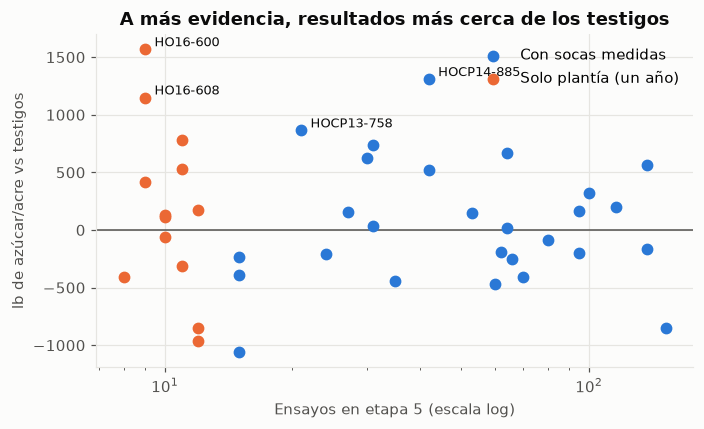

Clones con solo plantía en etapa 5: ['HO16-600', 'HO16-608', 'L13-251', 'HO13-708', 'HO15-971', 'HO11-532', 'HOCP14-802', 'HO17-738', 'HOCP17-701', 'HOCP13-740', 'CP01-1372', 'L08-090', 'HO11-515']


In [21]:
fig, ax = plt.subplots(figsize=(6.5, 4))
solo_plantia = clones5["ultimo_corte"] == 0
ax.axhline(0, color=TINTA2, linewidth=1)
ax.scatter(clones5.loc[~solo_plantia, "ensayos"], clones5.loc[~solo_plantia, "d_azucar_lb"], color=AZUL, s=45, label="Con socas medidas", zorder=3)
ax.scatter(clones5.loc[solo_plantia, "ensayos"], clones5.loc[solo_plantia, "d_azucar_lb"], color=NARANJA, s=45, label="Solo plantía (un año)", zorder=3)
for c in clones5.index[:4]:
    ax.annotate(c, (clones5.loc[c, "ensayos"], clones5.loc[c, "d_azucar_lb"]), textcoords="offset points", xytext=(6, 2), fontsize=8.5, color=TINTA)
ax.set_xscale("log"); ax.set_xlabel("Ensayos en etapa 5 (escala log)")
ax.set_ylabel("lb de azúcar/acre vs testigos")
ax.set_title("A más evidencia, resultados más cerca de los testigos")
ax.legend(frameon=False, loc="upper right")
guardar(fig, "serie1_08_evidencia.png")
print("Clones con solo plantía en etapa 5:", list(clones5.index[solo_plantia]))

**Hallazgo 12.** Los primeros lugares del ranking (HO16-600, HO16-608, L13-251…) se evaluaron en un
solo año y solo en plantía: no hay forma de saber su longevidad, y su ventaja puede ser suerte del año
(regresión a la media). Los clones con decenas de ensayos y socas medidas se acercan a los testigos.
**Decisión:** criterio mínimo de evidencia para recomendar ampliar una variedad
(se fija en el notebook 02): al menos 2 años en etapa 5 y socas medidas hasta soca 2.

### 5.9 Cobertura de variables secundarias

In [22]:
cob = df.groupby("YEAR")[["FIBER","POPN"]].apply(lambda g: g.notna().mean()).round(2)
display(cob.T)
print("Fibra medida en etapa 5:", round(df.loc[df.STAGE==5, "FIBER"].notna().mean(), 2))

YEAR,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021
FIBER,0.32,0.37,0.27,0.32,0.33,0.36,0.31,0.3,0.33,0.3,0.98,0.98
POPN,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.0,1.00,1.0,0.00,0.00


Fibra medida en etapa 5: 0.19


**Hallazgo 13.** La fibra solo se midió en ~30 % de las filas de 2010-2019 y en 19 % de la etapa 5.
Para el ingenio la fibra importa (bagazo para cogeneración), pero con esta cobertura **no es criterio
de selección**: se reporta como descriptivo donde exista y se recomienda medirla siempre en los
ensayos propios (pregunta 4).

**Variables que no pueden usarse para predecir:** TCA, TRS_TON, POPN, MSTWT y FIBER se miden en la
misma cosecha que T_SPACRE (y T_SPACRE = TCA × TRS). Usarlas en el modelo supervisado sería fuga.

## 6. Resumen y decisiones para el notebook 02 (modelado)

| # | Hallazgo | Decisión |
|---|---|---|
| 1 | 36 % de filas partidas por coma decimal (2010-2019) | Reparación validada con identidad; loader propio |
| 2 | T_SPACRE en libras, no toneladas | Ingreso = T_SPACRE × precio (US$/lb) |
| 3 | POPN cambia de unidad en 2020; el archivo une 2 exportaciones | POPN 2020-21 → faltante; no se usa como predictor |
| 4 | Llaves repetidas = testigos en ensayos paralelos | Promediar a nivel parcela |
| 5 | Etapas 2-4 inflan el rendimiento ~50 % | Economía solo con etapa 5 |
| 6 | Lugar-año explica 4× más que la variedad | Comparar contra testigos del mismo ensayo |
| 7 | Sesgo de supervivencia en socas y etapas | Caída de socas dentro de clon, en etapa 5 |
| 8 | Caída ajustada: 93 / 80 / 72 / 65 % | Usar curva ajustada; no extrapolar más allá de soca 4 |
| 9 | La longevidad difiere entre variedades (p < 0.001) | Ranking = productividad + longevidad |
| 10 | Una parcela es muy ruidosa (r ≈ 0.4 entre reps) | Exigir evidencia en muchos ensayos |
| 11 | Ranking por azúcar ≈ ranking por margen | Rankear por azúcar; economía para el ciclo y el riesgo |
| 12 | Los mejores tienen menos evidencia | Mínimo: 2 años en etapa 5 y socas hasta soca 2 |
| 13 | Fibra con baja cobertura | Solo descriptiva; medirla en ensayos propios |

Tablas generadas en `outputs/tables/` y figuras en `outputs/figures/`.